<a href="https://colab.research.google.com/github/AndresMontesDeOca/vision_computadora_II/blob/VpC2_2026/YOLO11_CounterStrike_CT_T_CEIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import numpy as np
from IPython.display import Audio, display, HTML

sr = 44100
signal = np.full(sr, 1e-6, dtype=np.float32)

# Renderiza el audio y fuerza loop="loop" en el elemento HTML generado
display(Audio(signal, rate=sr, autoplay=True))
display(HTML("""
<script>
  const audios = document.querySelectorAll('audio');
  audios.forEach(a => { a.loop = true; a.play().catch(() => {}); });
</script>
"""))

# Detección de Jugadores CT vs. T en Counter-Strike con Ultralytics YOLO11
**Trabajo Práctico Final – Visión por Computadora II (CEIA)**

Esta notebook implementa un pipeline completo y reproducible para entrenar, evaluar y comparar modelos **Ultralytics YOLO11** de detección de objetos orientados a distinguir jugadores **Counter-Terrorist (CT)** y **Terrorist (T)** a partir del dataset público de Roboflow Universe:

- **Dataset:** [Counter-Strike (Roboflow Universe)](https://universe.roboflow.com/counter-strike-uovxc/counter-strike-h9y80/browse?queryText=&pageSize=100&startingIndex=0&browseQuery=true) (`counter-strike-uovxc/counter-strike-h9y80`)
- **Arquitectura:** [Ultralytics YOLO11](https://docs.ultralytics.com/models/yolo11)

### Alineación con las pautas del TP (CEIA)
1. **Eje Central (Obligatorio):** Detección de objetos con modelos pre-entrenados (`yolo11n`, `yolo11s`, opcionalmente `yolo11m` / `yolov8n` para ablación).
2. **Capacidad Adicional (Opcional valorada):** Seguimiento multi-objeto (**Object Tracking** con ByteTrack) + contador en vivo de jugadores CT/T y FPS.
3. **Métricas para el Paper IEEE:** Tabla comparativa con `mAP@50`, `mAP@50-95`, `Precision`, `Recall`, `F1-Score`, AP por clase, latencia (ms) y FPS, junto con matriz de confusión y curvas PR.
4. **Demo en Video (≤ 2 min):** Generación directa de un video `.mp4` anotado para la presentación en vivo.

### Antes de ejecutar en Google Colab
1. Ve a **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4 / L4 / A100)**.
2. Agrega tu API Key gratuita de Roboflow en el panel izquierdo de Colab (**Secretos 🔑**) con el nombre `ROBOFLOW_API_KEY` (si no la configuras allí, la celda te la pedirá de forma segura al ejecutarse).

## 1. Configuración del entorno, GPU y reproducibilidad

In [10]:
# Verificar GPU disponible en Colab / entorno local
!nvidia-smi

Thu Nov 26 18:07:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   72C    P0             33W /   70W |    3515MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [11]:
# Instalar dependencias principales
!pip install -q ultralytics roboflow supervision pandas matplotlib seaborn

In [12]:
import os
import time
import random
from pathlib import Path

import cv2
import yaml
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from ultralytics import YOLO

# Semilla global para reproducibilidad de experimentos
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print(f"PyTorch: {torch.__version__} | CUDA disponible: {torch.cuda.is_available()} | Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")

PyTorch: 2.14.1+cu130 | CUDA disponible: True | Device: 0
GPU detectada: Tesla T4


In [13]:
# (Opcional) Montar Google Drive para guardar pesos, métricas y videos de forma persistente
USE_GOOGLE_DRIVE = True  # Cambiar a True si deseas guardar todo en tu Google Drive

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/CEIA_CV2_CS_YOLO11")
else:
    PROJECT_DIR = Path("./ceia_cs_yolo11_runs")

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Directorio de resultados: {PROJECT_DIR.resolve()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Directorio de resultados: /content/drive/MyDrive/CEIA_CV2_CS_YOLO11


## 2. Descarga e inspección del dataset desde Roboflow Universe

El proyecto en Roboflow es `counter-strike-uovxc/counter-strike-h9y80`. El código detecta automáticamente la última versión disponible del dataset (o puedes fijar un número exacto en `DATASET_VERSION` para máxima reproducibilidad).

In [14]:
from getpass import getpass
from roboflow import Roboflow

# 1) Intentar leer la API Key desde Colab Secrets o variable de entorno
ROBOFLOW_API_KEY = os.environ.get("ROBOFLOW_API_KEY")
if not ROBOFLOW_API_KEY:
    try:
        from google.colab import userdata
        ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")
    except Exception:
        ROBOFLOW_API_KEY = None

if not ROBOFLOW_API_KEY:
    ROBOFLOW_API_KEY = getpass("Ingresa tu ROBOFLOW_API_KEY: ")

WORKSPACE_ID = "counter-strike-uovxc"
PROJECT_ID = "counter-strike-h9y80"
DATASET_VERSION = None  # Ej: 1, 2, ... Si es None, selecciona la última versión disponible

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace(WORKSPACE_ID).project(PROJECT_ID)

if DATASET_VERSION is None:
    versions = project.versions()
    if not versions:
        raise RuntimeError(
            "Este proyecto no tiene una versión generada en Roboflow. "
            "Forkea el dataset o genera una versión en Roboflow Universe antes de descargar."
        )
    # Tomar el número de versión más reciente
    DATASET_VERSION = max(int(v.version) for v in versions)

print(f"Descargando {WORKSPACE_ID}/{PROJECT_ID} (versión {DATASET_VERSION}) en formato yolov11...")
dataset = project.version(DATASET_VERSION).download("yolov11")
DATASET_DIR = Path(dataset.location)
DATA_YAML = DATASET_DIR / "data.yaml"
print(f"Dataset descargado en: {DATASET_DIR.resolve()}")
print(f"Archivo data.yaml: {DATA_YAML}")

loading Roboflow workspace...
loading Roboflow project...
Descargando counter-strike-uovxc/counter-strike-h9y80 (versión 1) en formato yolov11...
Dataset descargado en: /content/Counter-Strike-1
Archivo data.yaml: /content/Counter-Strike-1/data.yaml


Clases originales en data.yaml: {0: 'ct', 1: 't'}


,Split,Imágenes,Etiquetas (.txt),Bounding Boxes
0,train,2577,2577,3442
1,valid,736,736,998
2,test,368,368,479


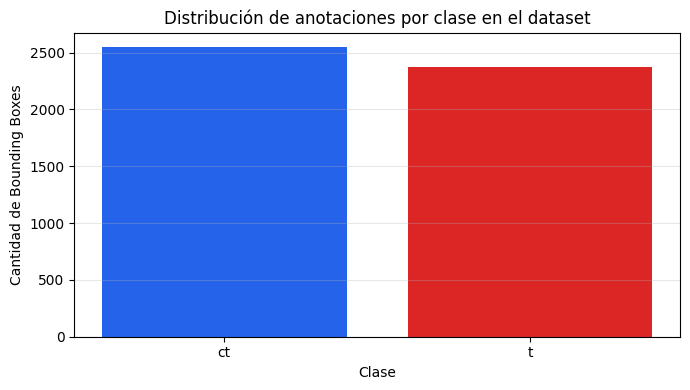

In [15]:
# Inspeccionar data.yaml, cantidad de imágenes por split y distribución de clases
with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)

class_names = data_cfg["names"]
if isinstance(class_names, list):
    id_to_name = {i: name for i, name in enumerate(class_names)}
else:
    id_to_name = {int(k): v for k, v in class_names.items()}

print("Clases originales en data.yaml:", id_to_name)

# Contar imágenes y anotaciones por split
split_summary = []
class_counts = {name: 0 for name in id_to_name.values()}

for split in ["train", "valid", "test"]:
    img_dir = DATASET_DIR / split / "images"
    lbl_dir = DATASET_DIR / split / "labels"
    if not img_dir.exists():
        continue
    imgs = list(img_dir.glob("*.*"))
    lbls = list(lbl_dir.glob("*.txt")) if lbl_dir.exists() else []
    boxes = 0
    for lbl_path in lbls:
        with open(lbl_path, "r", encoding="utf-8") as lf:
            for line in lf:
                parts = line.strip().split()
                if parts:
                    cid = int(parts[0])
                    boxes += 1
                    if cid in id_to_name:
                        class_counts[id_to_name[cid]] += 1
    split_summary.append({
        "Split": split,
        "Imágenes": len(imgs),
        "Etiquetas (.txt)": len(lbls),
        "Bounding Boxes": boxes,
    })

df_splits = pd.DataFrame(split_summary)
display(df_splits)

# Gráfico de distribución de clases (útil para la sección de Metodología del paper IEEE)
plt.figure(figsize=(7, 4))
palette = ["#2563eb", "#dc2626", "#16a34a", "#d97706", "#7c3aed", "#0891b2"]
colors = [palette[i % len(palette)] for i in range(len(class_counts))]
plt.bar(class_counts.keys(), class_counts.values(), color=colors)
plt.title("Distribución de anotaciones por clase en el dataset")
plt.xlabel("Clase")
plt.ylabel("Cantidad de Bounding Boxes")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(PROJECT_DIR / "class_distribution.png", dpi=150)
plt.show()

### (Opcional) Unificación / filtrado estricto a 2 clases: `CT` y `T`

Algunos datasets de Counter-Strike en Roboflow incluyen subclases (por ejemplo `ct_head`, `t_head`, `c4` o `ct_body`).
Si al inspeccionar `data.yaml` arriba ves más de 2 clases y quieres entrenar un detector binario puro **CT vs. T**, activa `ENABLE_BINARY_CT_T_REMAP = True` y ajusta el diccionario `CLASS_REMAP` según los nombres exactos impresos arriba.

In [16]:
import shutil

ENABLE_BINARY_CT_T_REMAP = False  # Cambiar a True si el dataset tiene subclases y quieres unificarlas a CT y T

# Ejemplo de mapeo (ajustar a los nombres exactos de tu data.yaml):
# 0 -> CT, 1 -> T. Cualquier clase no incluida aquí se descarta.
CLASS_REMAP = {
    "ct": 0,
    "CT": 0,
    "ct_body": 0,
    "ct_head": 0,
    "t": 1,
    "T": 1,
    "t_body": 1,
    "t_head": 1,
}

ACTIVE_DATA_YAML = DATA_YAML

if ENABLE_BINARY_CT_T_REMAP:
    REMAPPED_DIR = Path(f"{DATASET_DIR}_ct_t_binary")
    if REMAPPED_DIR.exists():
        shutil.rmtree(REMAPPED_DIR)
    shutil.copytree(DATASET_DIR, REMAPPED_DIR)

    id_remap = {
        orig_id: CLASS_REMAP[name]
        for orig_id, name in id_to_name.items()
        if name in CLASS_REMAP
    }
    print("Mapeo aplicado (ID original -> ID nuevo):", id_remap)

    for split in ["train", "valid", "test"]:
        lbl_dir = REMAPPED_DIR / split / "labels"
        if not lbl_dir.exists():
            continue
        for lbl_path in lbl_dir.glob("*.txt"):
            new_lines = []
            with open(lbl_path, "r", encoding="utf-8") as lf:
                for line in lf:
                    parts = line.strip().split()
                    if parts and int(parts[0]) in id_remap:
                        parts[0] = str(id_remap[int(parts[0])])
                        new_lines.append(" ".join(parts))
            with open(lbl_path, "w", encoding="utf-8") as lf:
                lf.write("\n".join(new_lines) + ("\n" if new_lines else ""))

    new_yaml = dict(data_cfg)
    new_yaml["path"] = str(REMAPPED_DIR.resolve())
    new_yaml["nc"] = 2
    new_yaml["names"] = ["CT", "T"]
    ACTIVE_DATA_YAML = REMAPPED_DIR / "data.yaml"
    with open(ACTIVE_DATA_YAML, "w", encoding="utf-8") as f:
        yaml.safe_dump(new_yaml, f, sort_keys=False)

    print(f"Nuevo data.yaml binario generado en: {ACTIVE_DATA_YAML}")
else:
    print(f"Usando data.yaml original sin modificaciones: {ACTIVE_DATA_YAML}")

Usando data.yaml original sin modificaciones: /content/Counter-Strike-1/data.yaml


## 3. Entrenamiento y comparación de arquitecturas (YOLO11n vs. YOLO11s)

Para justificar técnicamente la elección del modelo en el informe IEEE (como piden las pautas de CEIA), entrenamos al menos **dos variantes** bajo exactamente el mismo split e hiperparámetros:
- **`yolo11n.pt` (Nano):** Mínima latencia / máximos FPS (ideal para tiempo real).
- **`yolo11s.pt` (Small):** Mejor balance entre precisión (`mAP`) y velocidad.

*(Puedes agregar `"yolo11m.pt"` o `"yolov8n.pt"` a la lista `MODELS_TO_TRAIN` si quieres ampliar la tabla de ablación del paper.)*

In [17]:
# Hiperparámetros principales de entrenamiento
MODELS_TO_TRAIN = [
    "yolo11n.pt",  # Baseline liviano (máximos FPS)
    "yolo11s.pt",  # Variante intermedia (mayor mAP)
    "yolo11m.pt",  # Descomentar para evaluar modelo mediano
    # "yolov8n.pt",  # Descomentar para comparar generacionalmente YOLO11 vs YOLOv8
]


EPOCHS = 200       # Ajustar a 80-100 para el entrenamiento definitivo
IMGSZ = 640       # Resolución estándar YOLO11
BATCH = -1        # Usar -1 para AutoBatch según VRAM disponible
PATIENCE = 15     # Early stopping si no mejora mAP en validación

trained_weights = {}

for weights_name in MODELS_TO_TRAIN:
    run_name = Path(weights_name).stem + "_cs_ct_t"
    print(f"\n{'='*60}\nEntrenando {weights_name} -> {run_name}\n{'='*60}")

    model = YOLO(weights_name)
    results = model.train(
        data=str(ACTIVE_DATA_YAML),
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        patience=PATIENCE,
        device=DEVICE,
        seed=SEED,
        project=str(PROJECT_DIR),
        name=run_name,
        exist_ok=True,
        plots=True,
        verbose=True,
    )

    best_pt = Path(results.save_dir) / "weights" / "best.pt"
    trained_weights[run_name] = best_pt
    print(f"Mejor checkpoint guardado en: {best_pt}")


Entrenando yolo11n.pt -> yolo11n_cs_ct_t
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Counter-Strike-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_cs

## 4. Evaluación cuantitativa y tabla comparativa (Paper IEEE)

Evaluamos cada modelo sobre el conjunto de **`test`** (o `val` si el dataset no posee split `test`) y registramos:
- `mAP@50` y `mAP@50-95`
- `Precision`, `Recall` y `F1-Score`
- `AP@50` por clase (`CT` y `T`)
- Latencia de inferencia promedio (`ms/frame`) y velocidad (`FPS`)

In [18]:
# Determinar split de evaluación (prioriza 'test' si existe)
eval_split = "test" if (Path(ACTIVE_DATA_YAML).parent / "test" / "images").exists() else "val"
print(f"Evaluando modelos sobre el split: '{eval_split}'")

comparison_rows = []

for run_name, best_pt in trained_weights.items():
    model = YOLO(str(best_pt))
    metrics = model.val(
        data=str(ACTIVE_DATA_YAML),
        split=eval_split,
        imgsz=IMGSZ,
        device=DEVICE,
        plots=True,
        project=str(PROJECT_DIR),
        name=f"{run_name}_eval_{eval_split}",
        exist_ok=True,
    )

    precision = float(metrics.box.mp)
    recall = float(metrics.box.mr)
    f1_score = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
    map50 = float(metrics.box.map50)
    map50_95 = float(metrics.box.map)

    infer_ms = float(metrics.speed.get("inference", 0.0))
    total_ms = sum(float(v) for v in metrics.speed.values())
    fps = (1000.0 / total_ms) if total_ms > 0 else 0.0

    row = {
        "Modelo": run_name,
        "mAP@50": round(map50, 4),
        "mAP@50-95": round(map50_95, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-Score": round(f1_score, 4),
        "Inferencia (ms)": round(infer_ms, 2),
        "Total (ms)": round(total_ms, 2),
        "FPS": round(fps, 1),
    }

    # Agregar AP@50 por clase
    for idx, cname in metrics.names.items():
        if idx < len(metrics.box.ap50):
            row[f"AP@50 ({cname})"] = round(float(metrics.box.ap50[idx]), 4)

    comparison_rows.append(row)

df_metrics = pd.DataFrame(comparison_rows).sort_values(by="mAP@50-95", ascending=False)
display(df_metrics)

metrics_csv = PROJECT_DIR / f"comparativa_modelos_{eval_split}.csv"
df_metrics.to_csv(metrics_csv, index=False)
print(f"Tabla de métricas exportada a: {metrics_csv}")

Evaluando modelos sobre el split: 'test'
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 35.7±10.6 MB/s, size: 66.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/Counter-Strike-1/test/labels... 368 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 368/368 641.1it/s 0.6s
val: New cache created: /content/Counter-Strike-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 4.2it/s 5.5s
                   all        368        479      0.939      0.868      0.938      0.493
                    ct        219        246      0.937      0.874      0.951      0.491
                     t        202        233     

,Modelo,mAP@50,mAP@50-95,Precision,Recall,F1-Score,Inferencia (ms),Total (ms),FPS,AP@50 (ct),AP@50 (t)
2,yolo11m_cs_ct_t,0.9571,0.5177,0.9495,0.9374,0.9434,33.50,36.03,27.8,0.9675,0.9466
1,yolo11s_cs_ct_t,0.9468,0.5034,0.9473,0.9025,0.9243,11.10,14.56,68.7,0.9529,0.9406
0,yolo11n_cs_ct_t,0.9379,0.4928,0.9386,0.8683,0.9021,4.55,8.64,115.7,0.9514,0.9245


Tabla de métricas exportada a: /content/drive/MyDrive/CEIA_CV2_CS_YOLO11/comparativa_modelos_test.csv


Mejor modelo seleccionado por mAP@50-95: yolo11m_cs_ct_t (/content/drive/MyDrive/CEIA_CV2_CS_YOLO11/yolo11m_cs_ct_t/weights/best.pt)

--- results.png ---


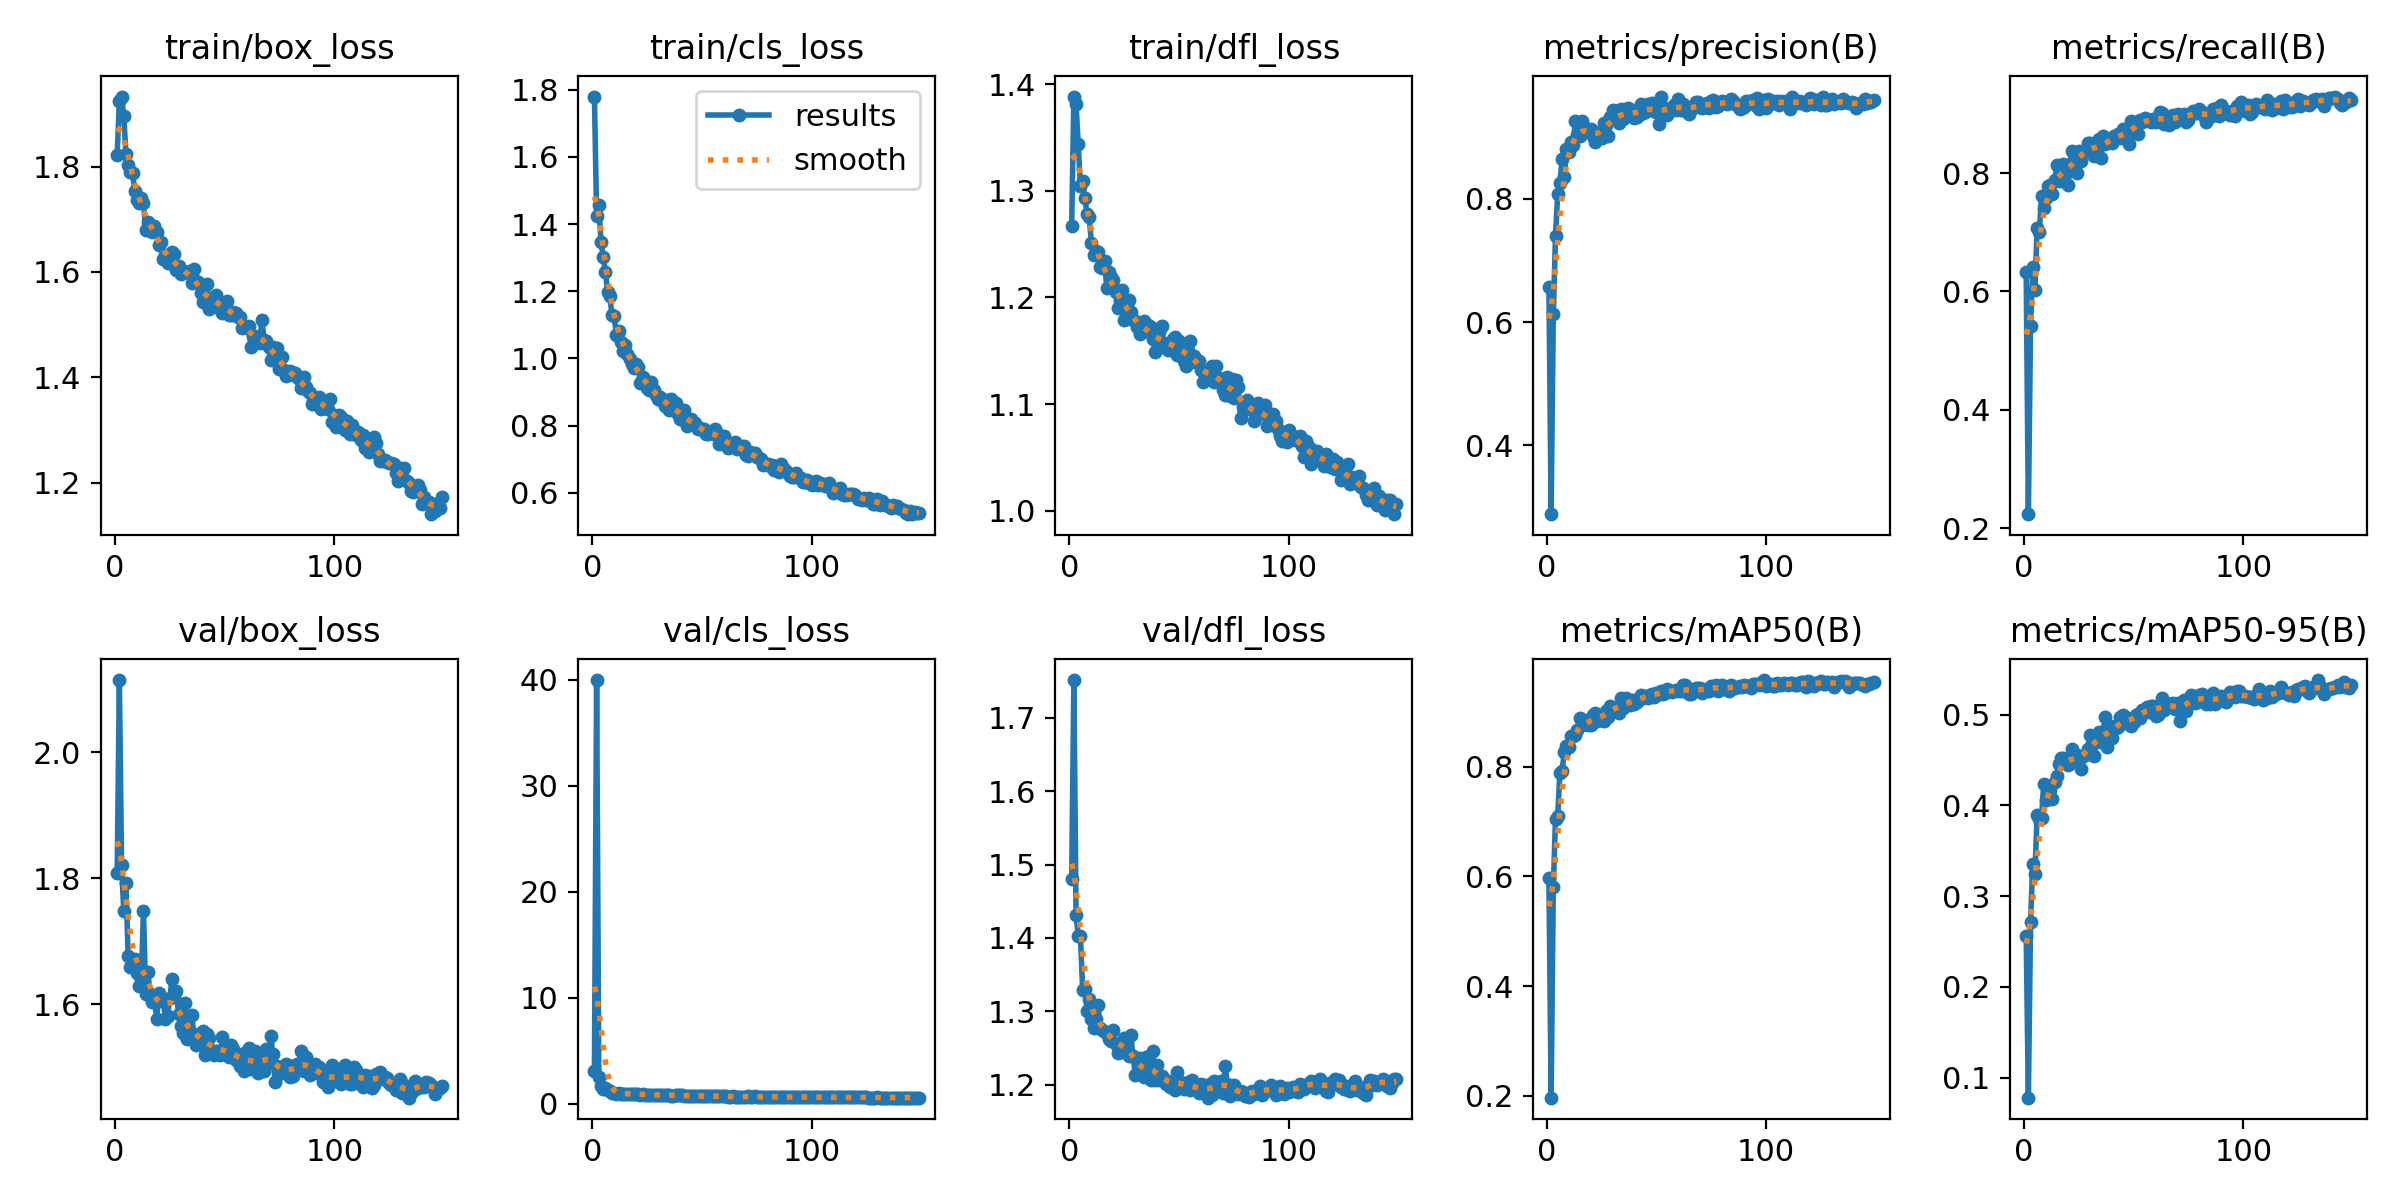


--- confusion_matrix_normalized.png ---


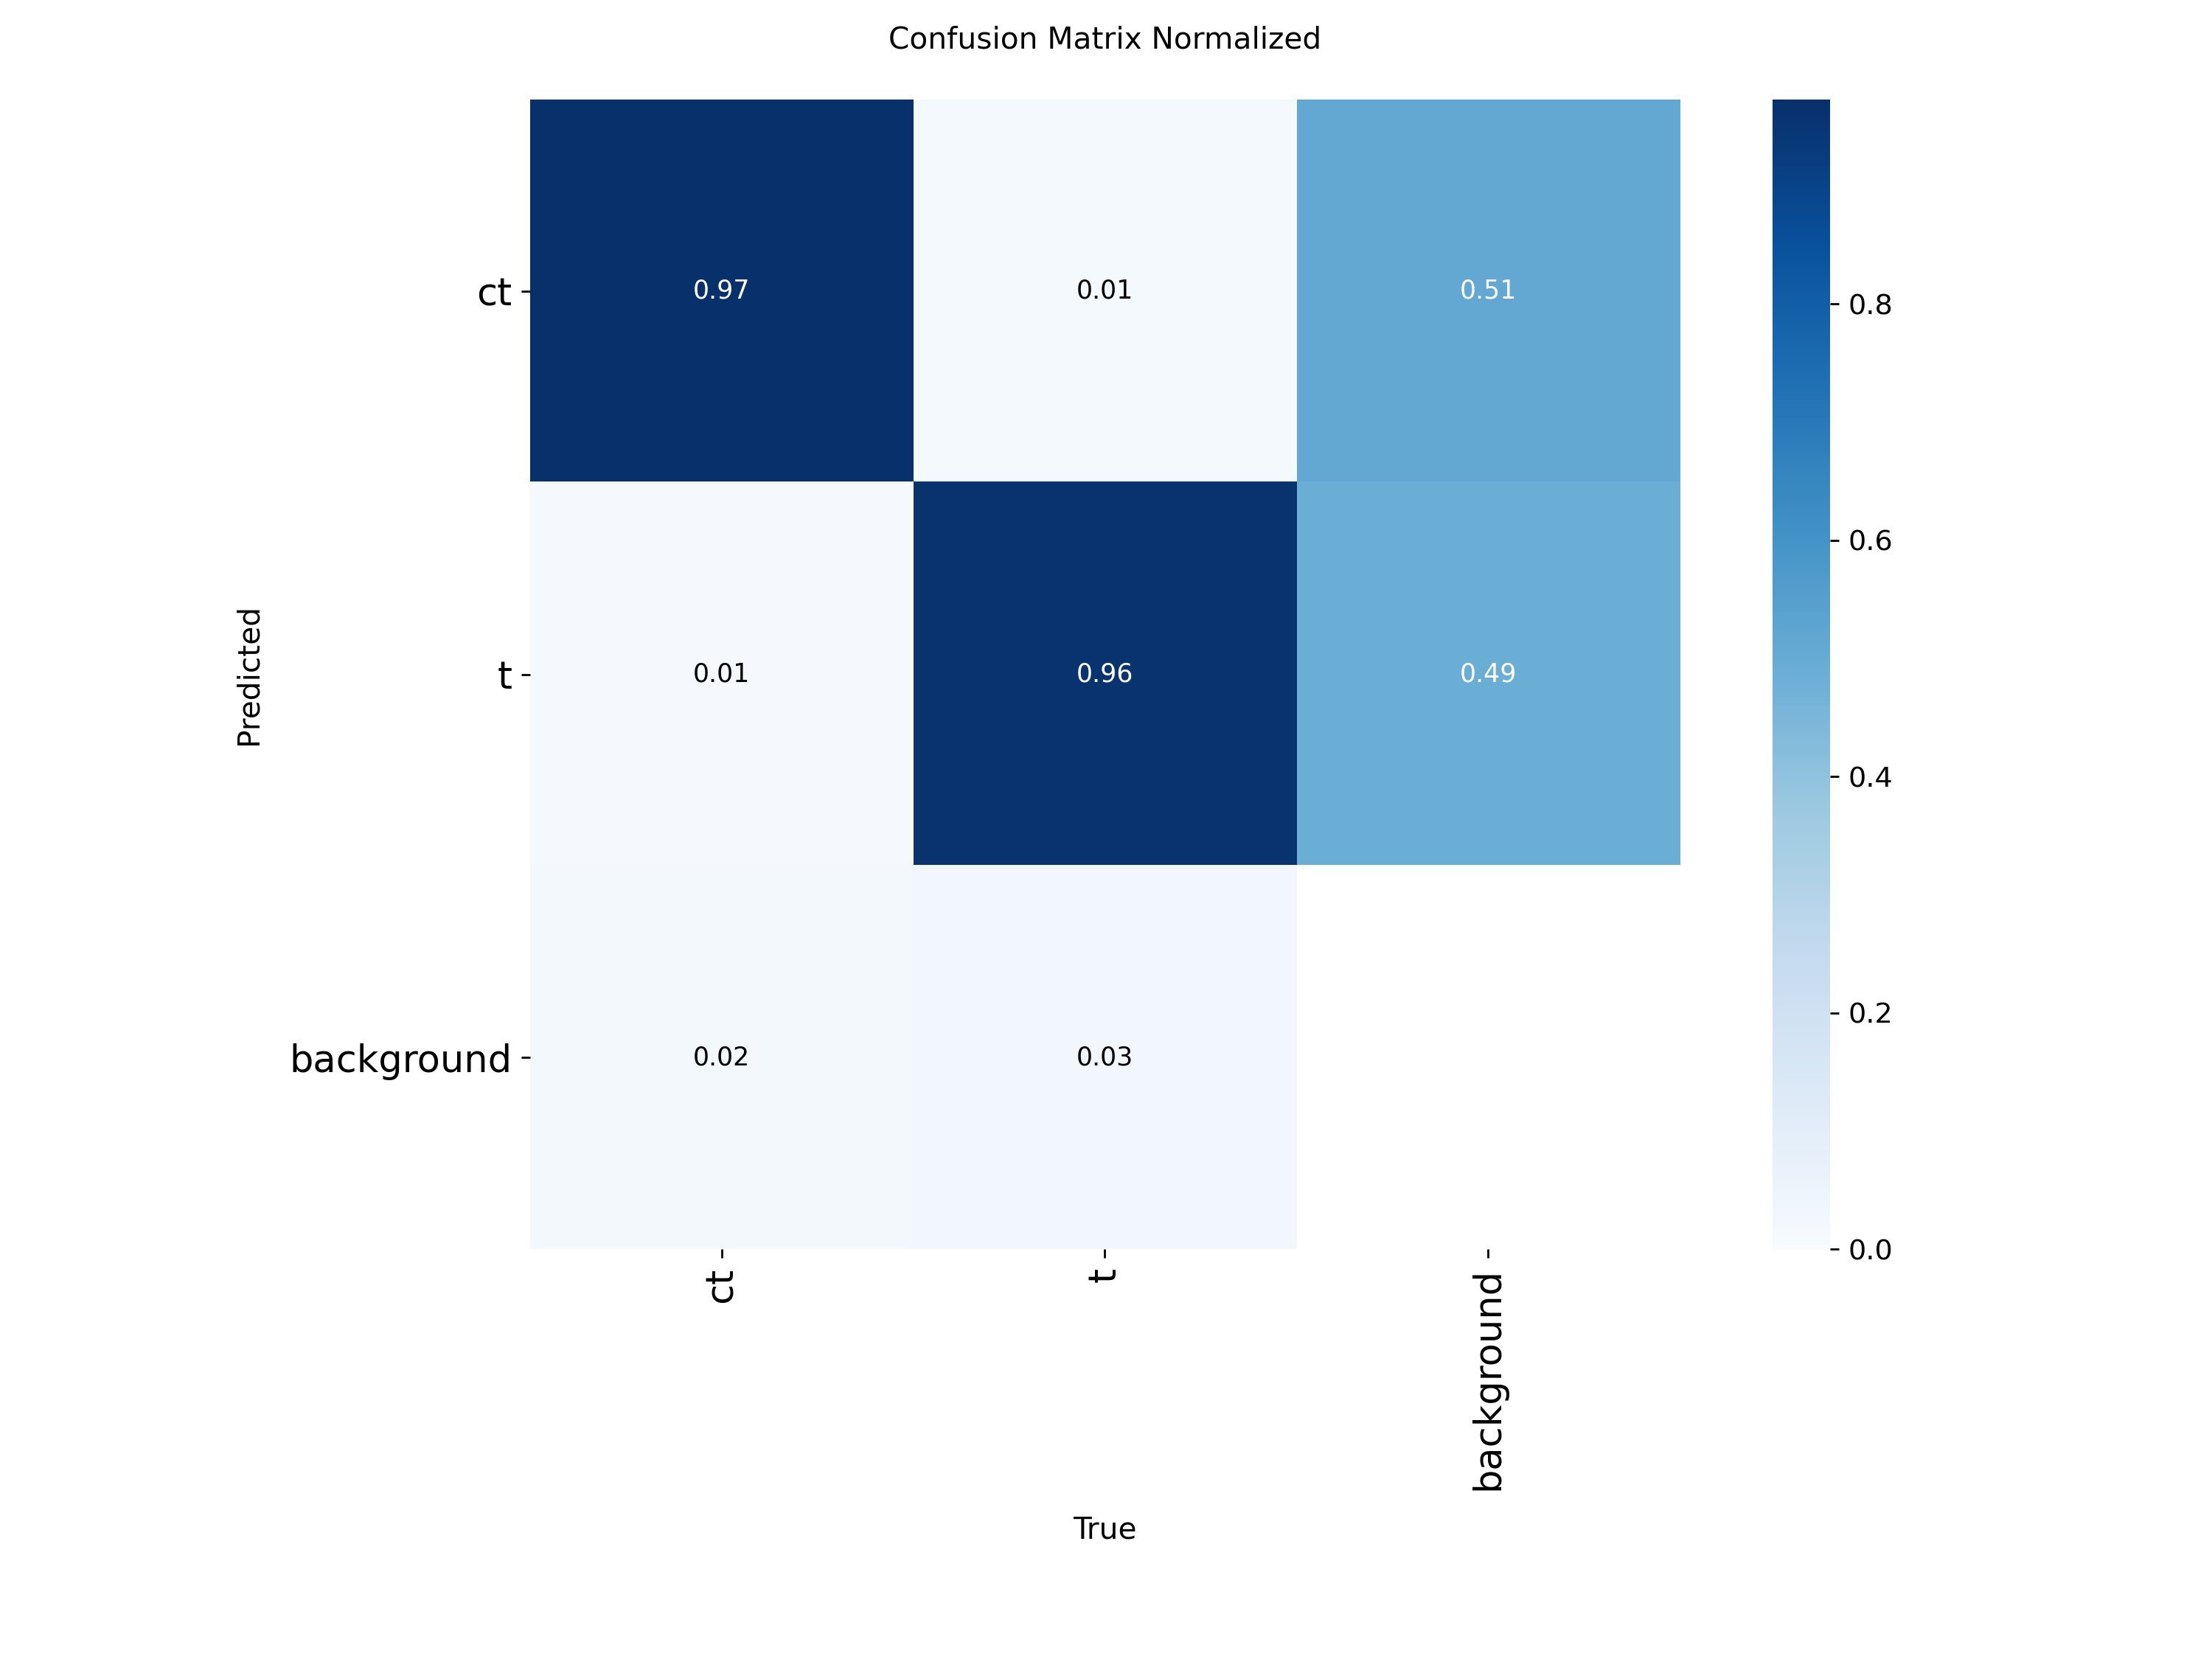


--- BoxPR_curve.png ---


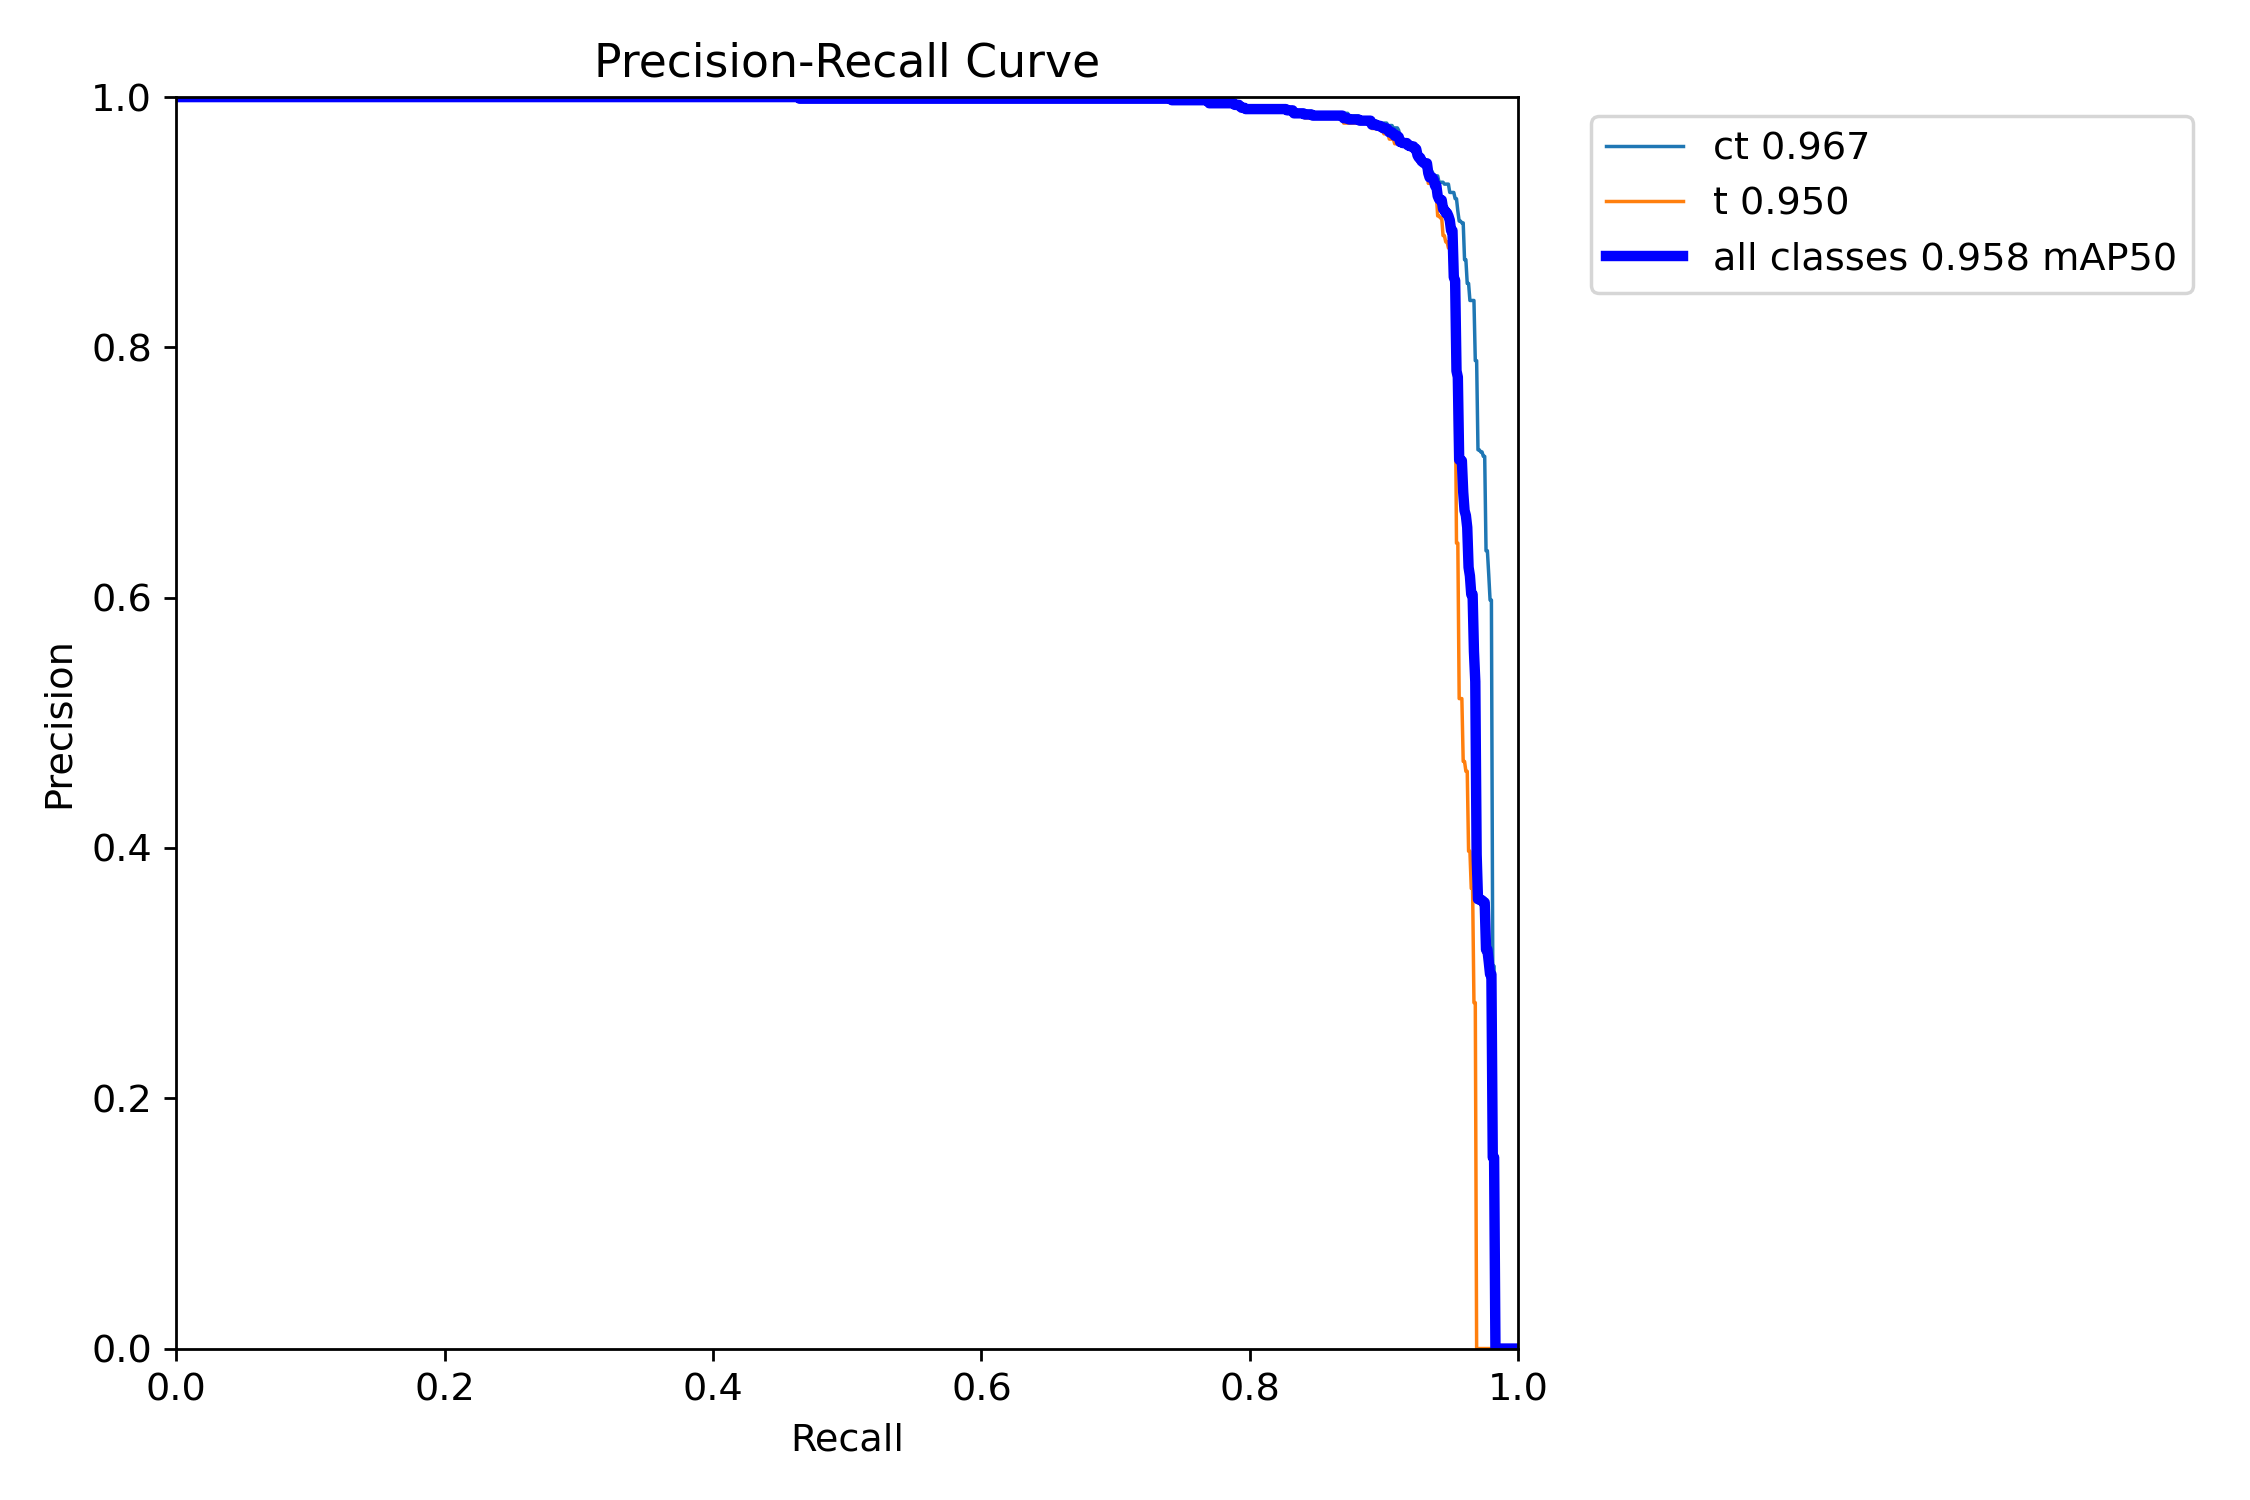

In [19]:
# Visualizar curvas de entrenamiento y matriz de confusión del mejor modelo
BEST_RUN_NAME = df_metrics.iloc[0]["Modelo"]
BEST_WEIGHTS = trained_weights[BEST_RUN_NAME]
BEST_RUN_DIR = BEST_WEIGHTS.parent.parent

print(f"Mejor modelo seleccionado por mAP@50-95: {BEST_RUN_NAME} ({BEST_WEIGHTS})")

for plot_name in ["results.png", "confusion_matrix_normalized.png", "BoxPR_curve.png"]:
    plot_path = BEST_RUN_DIR / plot_name
    if plot_path.exists():
        print(f"\n--- {plot_name} ---")
        display(Image(filename=str(plot_path), width=800))

## 5. Inferencia visual sobre imágenes de prueba


0: 640x640 1 ct, 31.3ms
1: 640x640 1 t, 31.3ms
2: 640x640 1 ct, 31.3ms
3: 640x640 1 t, 31.3ms
4: 640x640 1 t, 31.3ms
5: 640x640 1 ct, 31.3ms
Speed: 2.7ms preprocess, 31.3ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)


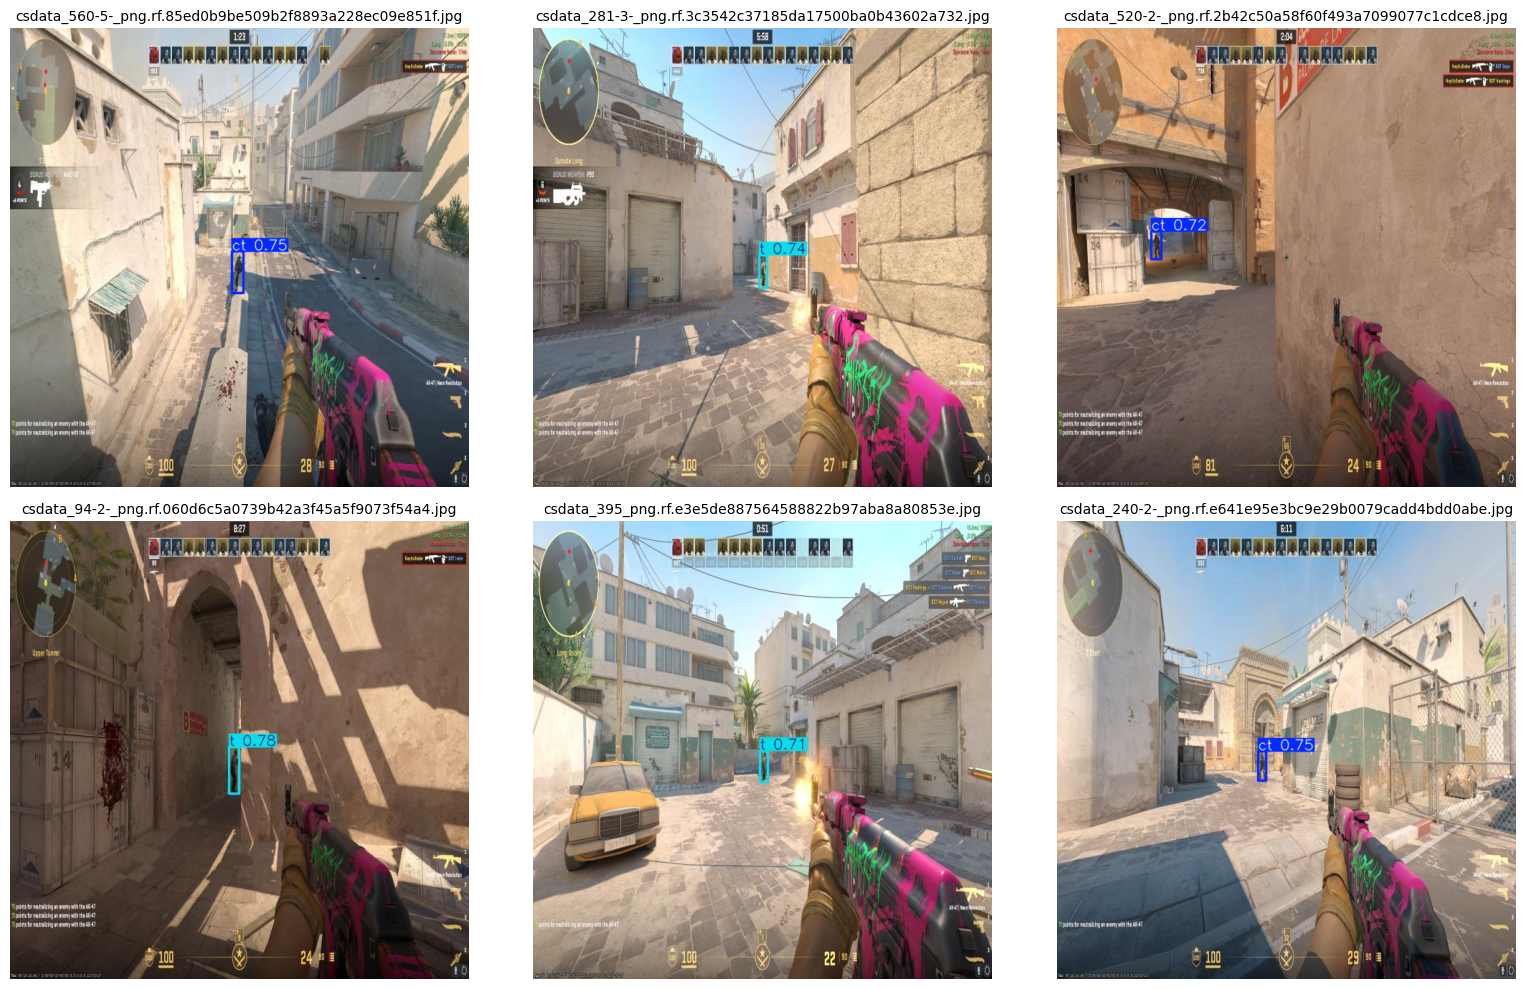

In [20]:
# Ejecutar predicciones sobre una muestra aleatoria del split de evaluación
best_model = YOLO(str(BEST_WEIGHTS))

test_img_dir = Path(ACTIVE_DATA_YAML).parent / eval_split / "images"
if not test_img_dir.exists():
    test_img_dir = Path(ACTIVE_DATA_YAML).parent / "valid" / "images"

all_test_imgs = list(test_img_dir.glob("*.*"))
sample_images = random.sample(all_test_imgs, k=min(6, len(all_test_imgs)))
preds = best_model.predict(source=[str(p) for p in sample_images], imgsz=IMGSZ, conf=0.35, device=DEVICE)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, result in zip(axes.flat, preds):
    plotted_bgr = result.plot()
    plotted_rgb = cv2.cvtColor(plotted_bgr, cv2.COLOR_BGR2RGB)
    ax.imshow(plotted_rgb)
    ax.set_title(Path(result.path).name, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.savefig(PROJECT_DIR / "sample_predictions.png", dpi=150)
plt.show()

## 6. Capacidad Adicional (Object Tracking) + Video Demo (≤ 2 min)

Las pautas de CEIA valoran muy positivamente integrar **Object Tracking** y solicitan un **video de de demostración de máximo 2 minutos**.

Esta celda aplica **ByteTrack** (`model.track(..., tracker="bytetrack.yaml")`) sobre un clip de gameplay de Counter-Strike (`.mp4`), dibuja cajas, clase (`CT` / `T`), ID persistente por jugador, conteo en vivo de CT vs. T en pantalla y FPS en tiempo real.

In [21]:
# Subir un video corto de gameplay de Counter-Strike (.mp4) o indicar su ruta local
VIDEO_INPUT_PATH = ""  # Ej: "/content/cs_gameplay_clip.mp4"

if not VIDEO_INPUT_PATH:
    try:
        # de-activated files.upload() to prevent notebook blockage
        # from google.colab import files
        # print("Selecciona un clip de gameplay (.mp4, idealmente 30s - 90s) para generar el video demo:")
        # uploaded = files.upload()
        # if uploaded:
        #     VIDEO_INPUT_PATH = next(iter(uploaded.keys()))
        pass
    except Exception:
        print("Define VIDEO_INPUT_PATH con la ruta a tu video .mp4 local.")

if VIDEO_INPUT_PATH and Path(VIDEO_INPUT_PATH).exists():
    VIDEO_OUTPUT_PATH = str(PROJECT_DIR / f"demo_tracking_{BEST_RUN_NAME}.mp4")

    cap = cv2.VideoCapture(VIDEO_INPUT_PATH)
    fps_in = cap.get(cv2.CAP_PROP_FPS) or 30.0
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(VIDEO_OUTPUT_PATH, fourcc, fps_in, (width, height))

    frame_idx = 0
    t_start = time.time()

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        t0 = time.perf_counter()
        results = best_model.track(
            frame,
            persist=True,
            tracker="bytetrack.yaml",
            imgsz=IMGSZ,
            conf=0.35,
            device=DEVICE,
            verbose=False,
        )
        dt = time.perf_counter() - t0
        inst_fps = 1.0 / dt if dt > 0 else 0.0

        res = results[0]
        annotated = res.plot()

        # Conteo de jugadores por clase en el frame actual
        counts = {}
        if res.boxes is not None and res.boxes.cls is not None:
            for cls_id in res.boxes.cls.int().tolist():
                cname = res.names[cls_id]
                counts[cname] = counts.get(cname, 0) + 1

        hud_text = f"{BEST_RUN_NAME} | FPS: {inst_fps:.1f} | " + " | ".join(
            f"{k}: {v}" for k, v in sorted(counts.items())
        )
        cv2.rectangle(annotated, (10, 10), (min(width - 10, 720), 50), (15, 23, 42), -1)
        cv2.putText(
            annotated,
            hud_text,
            (20, 38),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.75,
            (255, 255, 255),
            2,
            cv2.LINE_AA,
        )

        writer.write(annotated)
        frame_idx += 1

    cap.release()
    writer.release()
    elapsed = time.time() - t_start
    print(f"Video demo procesado ({frame_idx}/{total_frames} frames en {elapsed:.1f}s): {VIDEO_OUTPUT_PATH}")
else:
    print("No se cargó ningún video todavía. Sube un clip .mp4 y vuelve a ejecutar esta celda.")

No se cargó ningún video todavía. Sube un clip .mp4 y vuelve a ejecutar esta celda.


## 7. Exportación del modelo y generación de `requirements.txt` (GitHub)

In [22]:
# Exportar el mejor modelo a ONNX (opcional: format="engine" para TensorRT si hay GPU compatible)
onnx_path = best_model.export(format="onnx", imgsz=IMGSZ, dynamic=False, simplify=True)
print(f"Modelo exportado a ONNX en: {onnx_path}")

# Generar requirements.txt limpio para el repositorio GitHub
requirements_content = "\n".join([
    "ultralytics>=8.3.0",
    "roboflow>=1.1.0",
    "supervision>=0.23.0",
    "opencv-python>=4.9.0",
    "pandas>=2.0.0",
    "matplotlib>=3.8.0",
    "seaborn>=0.13.0",
    "pyyaml>=6.0.1",
    "onnx>=1.16.0",
])

req_path = PROJECT_DIR / "requirements.txt"
req_path.write_text(requirements_content + "\n", encoding="utf-8")
print(f"Archivo requirements.txt generado en: {req_path}")

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11m summary (fused): 125 layers, 20,031,574 parameters, 0 gradients, 67.8 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/CEIA_CV2_CS_YOLO11/yolo11m_cs_ct_t/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (38.7 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 462ms
Prepared 4 packages in 1.13s
Installed 4 packages in 55ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.32.0
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 2.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.2